In [1]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd

print("Python path:", sys.executable)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

2026-11-11 12:43:08.683196: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-11 12:43:10.132180: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-11 12:43:55.266703: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python path: /mnt/c/Users/valla/Downloads/my portfolio/CAPSTONE projects/rice-leaf-disease-detection/.venv/bin/python
TensorFlow: 2.20.0
NumPy: 2.4.6
Pandas: 3.1.1
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Rice Leaf Disease Detection Using Deep Learning

## 1. Introduction

Rice is one of the most important food crops in the world. Rice plants are affected by several diseases that can reduce crop quality and production.

The objective of this project is to develop a Deep Learning-based image classification model that identifies rice leaf diseases from images.

### Objectives
- Perform Exploratory Data Analysis (EDA) on the rice leaf image dataset.
- Preprocess and visualize rice leaf images.
- Develop Convolutional Neural Network (CNN) models.
- Experiment with Data Augmentation.
- Compare multiple models using evaluation metrics.
- Identify the best-performing model.

### Dataset Information

The dataset contains three disease categories:
1. Bacterial leaf blight
2. Brown spot
3. Leaf smut

**Dataset location:** `data/raw/Data/`

## Step 2: import Libraries

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading and Inspection

In [3]:
# Dataset location
DATASET_PATH = Path("../data/raw/Data")

# Disease classes
classes = [
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

# Supported image extensions
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

# Count images in each class
class_counts = {}

for disease in classes:

    folder = DATASET_PATH / disease

    images = [
        file for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in extensions
    ]

    class_counts[disease] = len(images)

# Display counts
for disease, count in class_counts.items():
    print(f"{disease}: {count} images")

print("-" * 40)
print("Total images:", sum(class_counts.values()))

Bacterial leaf blight: 40 images
Brown spot: 40 images
Leaf smut: 39 images
----------------------------------------
Total images: 119


## Step 4: Visualize Class Distribution

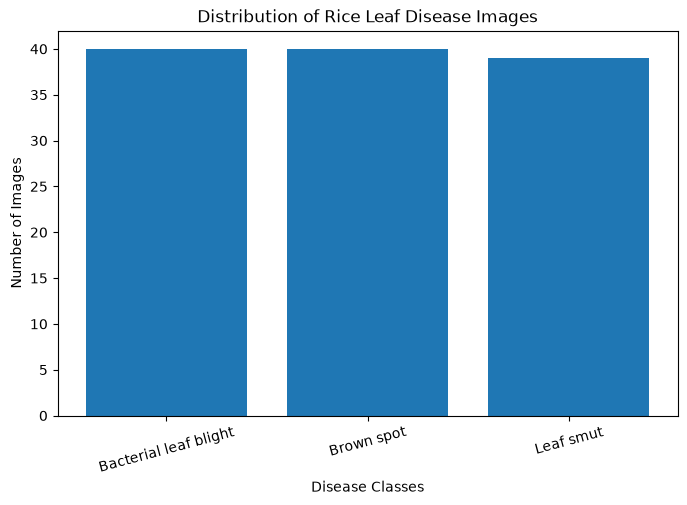

In [4]:
plt.figure(figsize=(8, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Distribution of Rice Leaf Disease Images")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)

plt.show()

## Step 5: Visualize Sample Images

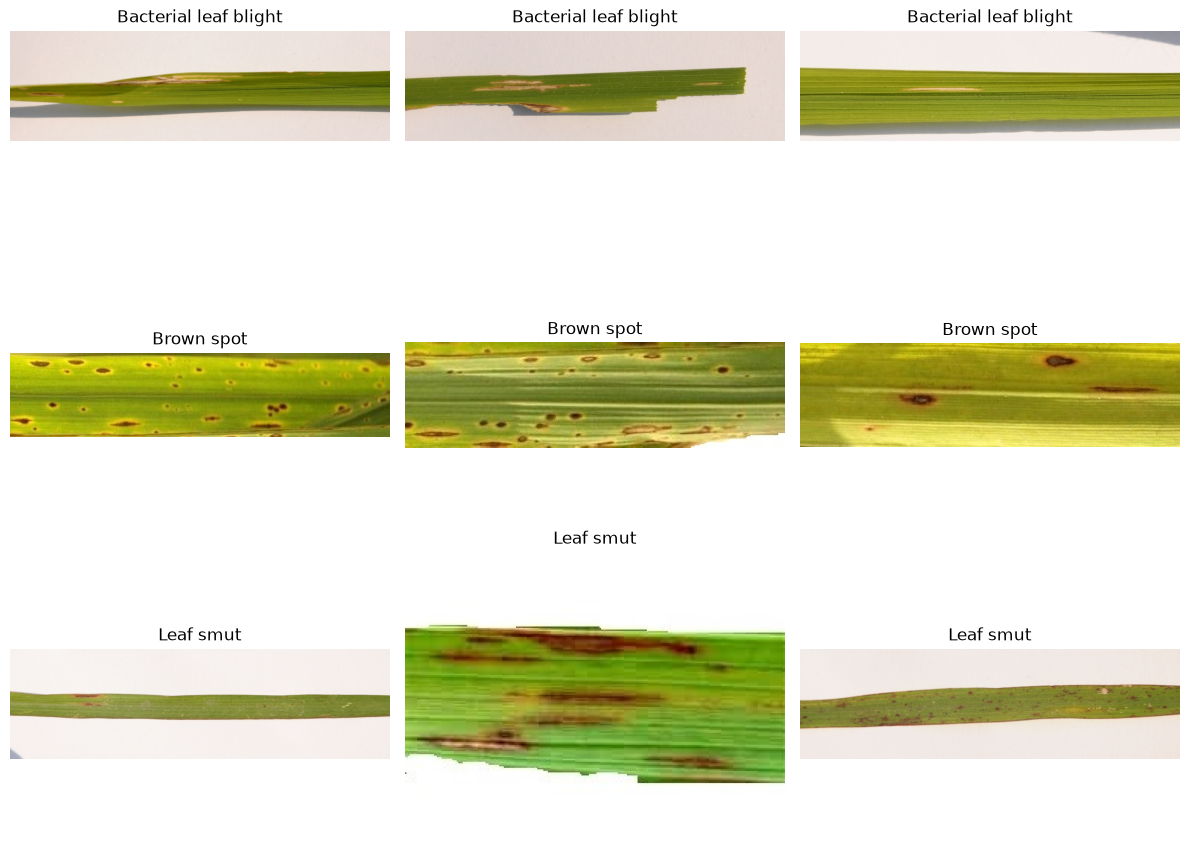

In [5]:
random.seed(42)

plt.figure(figsize=(12, 10))

for row, disease in enumerate(classes):

    folder = DATASET_PATH / disease

    images = [
        img for img in folder.glob("*")
        if img.suffix.lower() in extensions
    ]

    selected_images = random.sample(images, min(3, len(images)))

    for col, image_path in enumerate(selected_images):

        image = Image.open(image_path).convert("RGB")

        plt.subplot(3, 3, row * 3 + col + 1)
        plt.imshow(image)
        plt.title(disease)
        plt.axis("off")

plt.tight_layout()
plt.show()

## Step 6: Image dimensions and quality analysis

In [6]:
# to store image information
image_data = []

# check every disease folder
for disease in classes:
    folder = DATASET_PATH / disease

    for image_path in folder.rglob("*"): # here * means finds files inside the folder and its subfolders

        if image_path.is_file() and image_path.suffix.lower() in extensions:

            try:
                with Image.open(image_path) as img:

                    width,height = img.size #	Returns image width and height

                    image_data.append({
                        "Disease":disease,
                        "Image":image_path.name,
                        "Width":width,
                        "Height":height,
                        "Format":img.format, # Identifies JPEG, PNG, etc.
                        "Mode":img.mode # Identifies RGB, grayscale, etc.
                    })
            except Exception as e:
                print(f"Corrupted Image:{image_path}")
                print(e)

# convert all collected informtaion into DataFrame
df_images = pd.DataFrame(image_data)

print("Image information collected successfully!")
print("Total readable images:", len(df_images))

df_images.head()


Image information collected successfully!
Total readable images: 119


,Disease,Image,Width,Height,Format,Mode
0,Bacterial leaf blight,DSC_0365.JPG,3081,897,JPEG,RGB
1,Bacterial leaf blight,DSC_0366.jpg,3081,897,JPEG,RGB
2,Bacterial leaf blight,DSC_0367.JPG,3081,897,JPEG,RGB
3,Bacterial leaf blight,DSC_0370.jpg,3081,897,JPEG,RGB
4,Bacterial leaf blight,DSC_0372.JPG,3081,897,JPEG,RGB


In [7]:
df_images.info()

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Disease  119 non-null    str  
 1   Image    119 non-null    str  
 2   Width    119 non-null    int64
 3   Height   119 non-null    int64
 4   Format   119 non-null    str  
 5   Mode     119 non-null    str  
dtypes: int64(2), str(4)
memory usage: 5.7 KB


# 6.1 Analyze Image dimensions

In [8]:
df_images[["Width","Height"]].describe()

,Width,Height
count,119.000000,119.000000
mean,2383.638655,707.739496
std,1123.528972,311.657582
min,250.000000,71.000000
25%,1074.000000,377.000000
50%,3081.000000,897.000000
75%,3081.000000,897.000000
max,3081.000000,900.000000


# 6.2 Check unique image dimensions

In [9]:
dimension_counts = (
    df_images.groupby(["Width", "Height"])
    .size()
    .reset_index(name="Count")
)

dimension_counts

,Width,Height,Count
0,250,200,2
1,286,92,1
2,296,88,1
3,301,71,1
4,311,170,1
5,316,127,1
6,340,94,1
7,359,168,1
8,367,73,1
9,376,80,1


# 6.3 Analyze Image Formats

In [10]:
print("Image formats:")
print(df_images["Format"].value_counts())

print("\nImage colour modes:")
print(df_images["Mode"].value_counts())

Image formats:
Format
JPEG    119
Name: count, dtype: int64

Image colour modes:
Mode
RGB    119
Name: count, dtype: int64


# 6.4 Visualize Image Dimensions

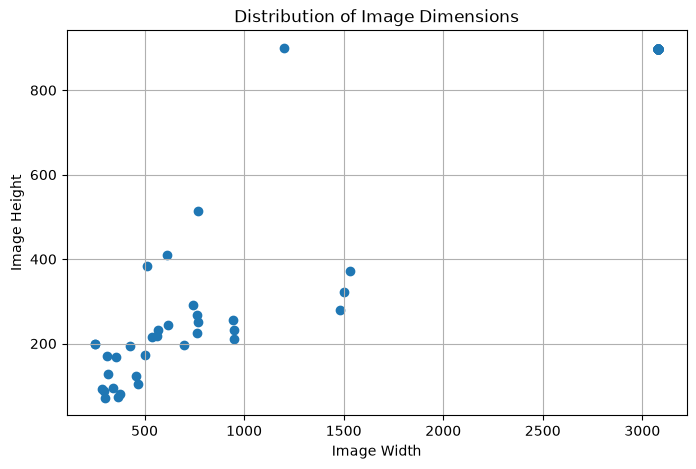

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_images["Width"],
    df_images["Height"]
)

plt.xlabel("Image Width")
plt.ylabel("Image Height")
plt.title("Distribution of Image Dimensions")

plt.grid(True)
plt.show()

In [12]:
df_images.head()

,Disease,Image,Width,Height,Format,Mode
0,Bacterial leaf blight,DSC_0365.JPG,3081,897,JPEG,RGB
1,Bacterial leaf blight,DSC_0366.jpg,3081,897,JPEG,RGB
2,Bacterial leaf blight,DSC_0367.JPG,3081,897,JPEG,RGB
3,Bacterial leaf blight,DSC_0370.jpg,3081,897,JPEG,RGB
4,Bacterial leaf blight,DSC_0372.JPG,3081,897,JPEG,RGB


In [13]:
print(df_images["Format"].value_counts())
print(df_images["Mode"].value_counts())

Format
JPEG    119
Name: count, dtype: int64
Mode
RGB    119
Name: count, dtype: int64


## Step 7. Image Preprocessing and Resizing

Since the images have different dimensions, we need to resize them to a common input size before training the CNN model.

We will use 224 × 224 pixels while preserving the original aspect ratio to avoid distorting the leaf images.

Our target is to convert every image into a consistent shape of 224 × 224 × 3, while preserving the original leaf shape.

# step 7.1 import tensorflow

In [14]:
import tensorflow as tf

# step 7.2 creating the preprocessing function

In [15]:
def preprocess_image(image_path, target_size=(224,224)):

    # load the image
    image = tf.keras.utils.load_img(image_path)

    # convert the image into a numerical array of pixel values
    image = tf.keras.utils.img_to_array(image)

    # resize while preserving the aspect ratio using padding
    image = tf.image.resize_with_pad(
        image,
        target_size[0],
        target_size[1]
    )

    # Normalize the pixel values between 0 and 1
    image = image / 255.0

    return image

# test the preprocess function

In [16]:
# Select one image
sample_image_path = (
    DATASET_PATH / "Bacterial leaf blight" / "DSC_0365.JPG"
)

# Preprocess the image
processed_image = preprocess_image(sample_image_path)

# Display image information
print("Image shape:", processed_image.shape)
print("Minimum pixel value:", tf.reduce_min(processed_image).numpy())
print("Maximum pixel value:", tf.reduce_max(processed_image).numpy())

I0000 00:00:1794401090.945621   33407 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Image shape: (224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.9343726


# Display the Processed Image

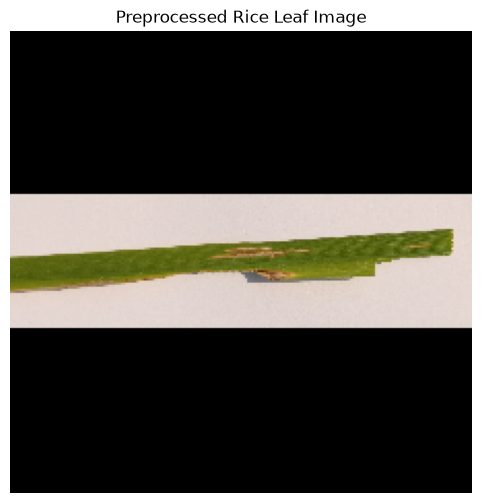

In [17]:
plt.figure(figsize=(6, 6))

plt.imshow(processed_image)

plt.title("Preprocessed Rice Leaf Image")
plt.axis("off")

plt.show()

# Step 7.3 Preprocess the Complete dataset

In [18]:
# store processed images and their labels
processed_images = []
image_labels = []

# create numerical labels for each disease
class_to_index ={
    disease: index
    for index,disease in enumerate(classes)
}

# process images from every disease folder
for disease in classes:
    folder = DATASET_PATH / disease

    image_paths = sorted([
       path for path in folder.rglob("*")
       if path.is_file() and path.suffix.lower() in extensions
    ])

    for image_path in image_paths:
        # preprocess the image
        image = preprocess_image(image_path)

        # store image and corresponding label
        processed_images.append(image.numpy())
        image_labels.append(class_to_index[disease])

# Convert lists into NumPy arrays
X = np.array(processed_images, dtype=np.float32)
y = np.array(image_labels, dtype=np.int32)

# Display dataset information
print("Image data shape:", X.shape)
print("Label data shape:", y.shape)
print("Total processed images:", len(X))

print("\nClass mapping:")
print(class_to_index)

print("\nLabel distribution:")
print(pd.Series(y).value_counts().sort_index())

Image data shape: (119, 224, 224, 3)
Label data shape: (119,)
Total processed images: 119

Class mapping:
{'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}

Label distribution:
0    40
1    40
2    39
Name: count, dtype: int64


## Step 8: Training and Testing the Dataset

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
# split the dataset

# first split: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y # Maintains class proportions in the split.
)

# Second split: Divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp # Maintains class proportions when dividing the temporary set.
)

# Display dataset shapes
print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training images: (83, 224, 224, 3)
Validation images: (18, 224, 224, 3)
Testing images: (18, 224, 224, 3)

Training labels: (83,)
Validation labels: (18,)
Testing labels: (18,)


In [21]:
# Verify Disease Distribution

# Create a distribution table for all three datasets
distribution = pd.DataFrame({
    "Disease": classes,

    "Training": [
        np.sum(y_train == i) for i in range(len(classes))
    ],

    "Validation": [
        np.sum(y_val == i) for i in range(len(classes))
    ],

    "Testing": [
        np.sum(y_test == i) for i in range(len(classes))
    ]
})

# Display distribution
print(distribution)

                 Disease  Training  Validation  Testing
0  Bacterial leaf blight        28           6        6
1             Brown spot        28           6        6
2              Leaf smut        27           6        6


## Step 9. Baseline CNN Model Development

In [22]:
# create the baseline CNN model
baseline_model = tf.keras.Sequential([

    # input layer Accepts 224 × 224 RGB images.
    tf.keras.layers.Input(shape=(224,224,3)),

    # First Convolution block
    tf.keras.layers.Conv2D(32, (3,3) ,activation="relu"), # Extracts visual features from images.
    tf.keras.layers.MaxPooling2D((2,2)), # Reduces feature-map dimensions.

    # Second Convolution block
    tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2,2)),

    # Third convolution block
    tf.keras.layers.Conv2D(128, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2,2)),


    # freduce the feature maps
    tf.keras.layers.GlobalAveragePooling2D(), # Summarizes extracted features.


    # fully connected layer
    tf.keras.layers.Dense(64, activation="relu"),

    # reduce Overfitting
    tf.keras.layers.Dropout(0.3), # Learns relationships between features.


    # output layer: 3 disease classes
    tf.keras.layers.Dense(3, activation="softmax") # Produces probabilities for the three disease classes.

])

In [23]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the CNN model
Before training, we need to configure three things:
1. Optimizer: Adam updates the model's weights to improve predictions.
2. Loss function: Measures how far predictions are from the correct labels.
3. Metric: Tracks classification accuracy.

In [24]:
baseline_model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    loss = "sparse_categorical_crossentropy",
    metrics = ['accuracy']
)

### step 9.1 Baseline CNN Model Training

In [25]:
# Stop training if validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the baseline CNN
history = baseline_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20, #One epoch means the model has processed the entire training dataset once.
    batch_size=8, # Batch size 8 means the model processes 8 images
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20


2026-11-11 12:45:08.820945: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f35f001b380 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-11 12:45:08.821000: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6
2026-11-11 12:45:08.933197: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-11 12:45:10.590961: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92801


 5/11 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4750 - loss: 1.0983

I0000 00:00:1794401117.909067   34045 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


11/11 ━━━━━━━━━━━━━━━━━━━━ 18s 801ms/step - accuracy: 0.3494 - loss: 1.1108 - val_accuracy: 0.3333 - val_loss: 1.0993
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3855 - loss: 1.0953 - val_accuracy: 0.4444 - val_loss: 1.0952
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4337 - loss: 1.0838 - val_accuracy: 0.3333 - val_loss: 1.0920
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.2771 - loss: 1.1258 - val_accuracy: 0.3333 - val_loss: 1.0951
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3614 - loss: 1.1014 - val_accuracy: 0.3333 - val_loss: 1.0898
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3614 - loss: 1.0984 - val_accuracy: 0.3333 - val_loss: 1.0790
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3373 - loss: 1.0859 - val_accuracy: 0.3333 - val_loss: 1.0643
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3494 - loss: 1.0793 - val_accuracy: 0.3333 - val_loss: 

### 9.2 Training and Validation Performance

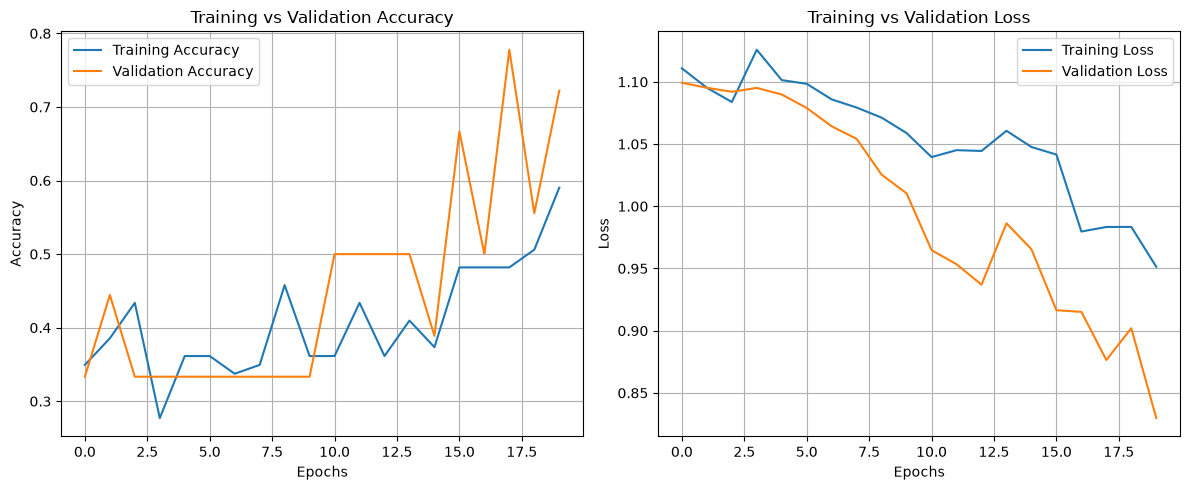

In [26]:
# Extract training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

# Plot accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 9.3 Baseline CNN Test Evaluation

In [27]:
# Evaluate the model using unseen test images
test_loss, test_accuracy = baseline_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

2026-11-11 12:45:33.952082: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-11-11 12:45:34.974714: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_101', 28 bytes spill stores, 28 bytes spill loads



1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5556 - loss: 1.0523
Test Loss: 1.0522793531417847
Test Accuracy: 55.55555820465088 %


### 9.4 Classification Report and Confusion Matrix

In [28]:
from sklearn.metrics import classification_report, confusion_matrix

# generate predictions
y_pred_prob = baseline_model.predict(X_test)

# convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob,axis=1)

# display classification report
print(classification_report(
    y_test,
    y_pred,
    labels=[0,1,2],
    target_names=classes,
    zero_division=0
    ))


"""
Metric	Meaning
Precision -- Of the images predicted as a disease, how many were correct?
Recal -- Of the actual images belonging to a disease, how many were identified?
F1-scor -- Balance between precision and recall.
Support --	Number of actual test images belonging to each disease.
"""

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 737ms/step
                       precision    recall  f1-score   support

Bacterial leaf blight       0.44      0.67      0.53         6
           Brown spot       0.50      0.17      0.25         6
            Leaf smut       0.71      0.83      0.77         6

             accuracy                           0.56        18
            macro avg       0.55      0.56      0.52        18
         weighted avg       0.55      0.56      0.52        18



'\nMetric\tMeaning\nPrecision -- Of the images predicted as a disease, how many were correct?\nRecal -- Of the actual images belonging to a disease, how many were identified?\nF1-scor -- Balance between precision and recall.\nSupport --\tNumber of actual test images belonging to each disease.\n'

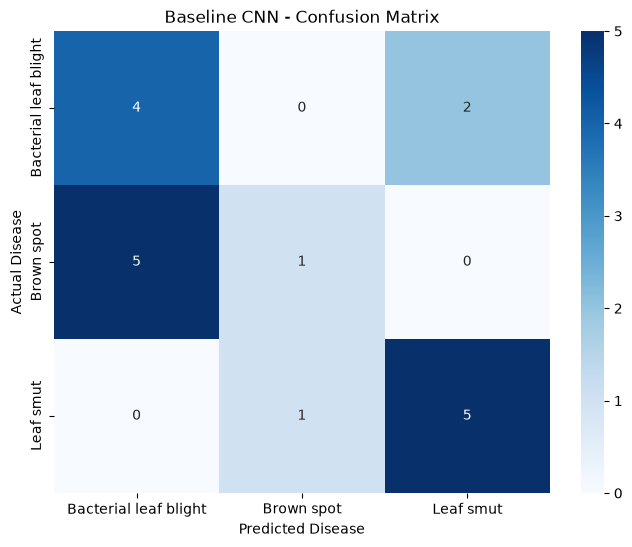

In [29]:
# create the confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Baseline CNN - Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.show()

### Baseline CNN - Observations

1. The baseline CNN achieved 55.56% test accuracy.
2. The macro F1-score was 0.51.
3. Leaf smut had the highest recall of 0.83.
4. Brown spot had the lowest recall of 0.17.
5. Most Brown spot images were misclassified as Bacterial leaf blight.
6. The small dataset size may limit the model's generalization ability.

Conclusion:
The baseline CNN provides an initial classification result, but its performance requires improvement. Data augmentation and transfer learning will be investigated.

## Step 10: data augmentation

Data augmentation creates modified versions of existing training images without changing their disease labels.

For example, we can take one rice leaf image and:
- Flip it horizontally.
- Rotate it slightly.
- Zoom in or out.
This helps the CNN learn from different visual variations and may improve its ability to generalize to new images.

Important: We will augment only the training images. Validation and test images will remain unchanged.

### 10.1 Creating Data Augmentation Layers

In [30]:
# Create data augmentation pipeline
data_augmentation = tf.keras.Sequential([

    # Randomly flip images horizontally
    tf.keras.layers.RandomFlip("horizontal"), # from left to right

    # Randomly rotates the image by up to approximately 36 degrees in either direction.
    tf.keras.layers.RandomRotation(0.1),

    # Randomly zoom images
    tf.keras.layers.RandomZoom(0.1) #Randomly zooms in or out by up to approximately 10%

], name="data_augmentation")

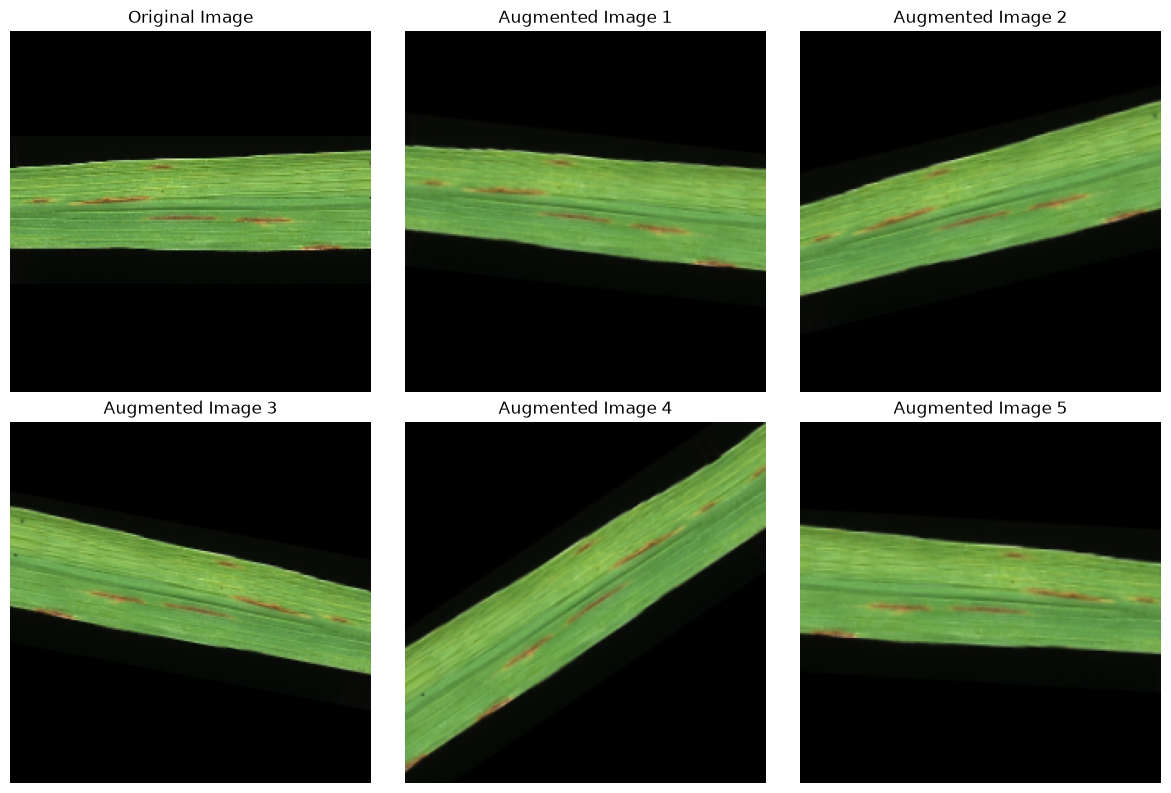

In [31]:
# Select one training image
sample_image = X_train[0]

# Display original and augmented images
plt.figure(figsize=(12, 8))

for i in range(6):

    if i == 0:
        augmented_image = sample_image
        title = "Original Image"

    else:
        augmented_image = data_augmentation(
            tf.expand_dims(sample_image, axis=0),
            training=True
        )[0].numpy()

        title = f"Augmented Image {i}"

    plt.subplot(2, 3, i + 1)
    plt.imshow(augmented_image)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

### 10.2 Augmented CNN Model Development

In [32]:
# Create augmented CNN model
""" 
Model 1: Baseline CNN (without augmentation).
Model 2: Augmented CNN (with augmentation).
"""
augmented_model = tf.keras.Sequential([

    # Input layer
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation, #Augmented CNN

    # First convolution block
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolution block
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third convolution block
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Feature extraction
    tf.keras.layers.GlobalAveragePooling2D(),

    # Fully connected layer
    tf.keras.layers.Dense(64, activation="relu"),

    # Dropout
    tf.keras.layers.Dropout(0.3),

    # Output layer
    tf.keras.layers.Dense(3, activation="softmax")

], name="Augmented_CNN")

In [33]:
augmented_model.summary()

Model: "Augmented_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

### 10.3 Augmented CNN Compilation

In [34]:
augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#We are using the same optimizer, learning rate and loss function as the baseline CNN. This makes our comparison more consistent.

### 10.4 Augmented CNN Model Training

In [35]:
# Early stopping
augmented_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train augmented CNN
augmented_history = augmented_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=8,
    callbacks=[augmented_early_stopping],
    verbose=1
)

Epoch 1/20


11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.2771 - loss: 1.1132 - val_accuracy: 0.3889 - val_loss: 1.0974
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2771 - loss: 1.0988 - val_accuracy: 0.3333 - val_loss: 1.0976
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3373 - loss: 1.1006 - val_accuracy: 0.3333 - val_loss: 1.0979
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2410 - loss: 1.1002 - val_accuracy: 0.5000 - val_loss: 1.0975
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3855 - loss: 1.0970 - val_accuracy: 0.3333 - val_loss: 1.0973
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3735 - loss: 1.0977 - val_accuracy: 0.3333 - val_loss: 1.0963
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3494 - loss: 1.0987 - val_accuracy: 0.3333 - val_loss: 1.0955
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3253 - loss: 1.0974 - val_accuracy: 0.3333 - val_loss: 1

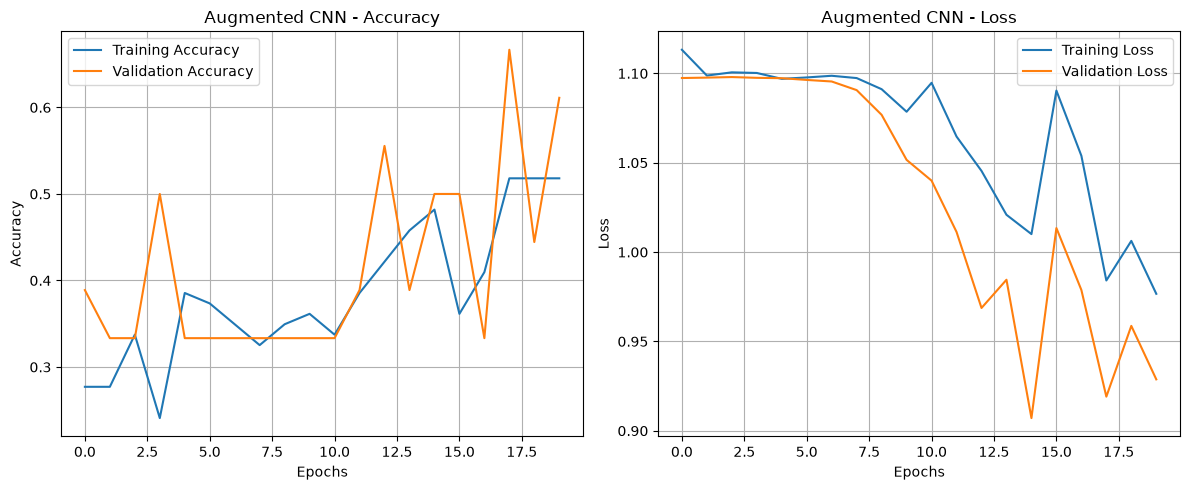

In [36]:
# Extract augmented model history
train_accuracy = augmented_history.history["accuracy"]
val_accuracy = augmented_history.history["val_accuracy"]

train_loss = augmented_history.history["loss"]
val_loss = augmented_history.history["val_loss"]

# Plot performance
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.title("Augmented CNN - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("Augmented CNN - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [37]:
# evaluate the augmented CNN

aug_test_loss, aug_test_accuracy = augmented_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Augmented CNN Test Loss:", aug_test_loss)
print("Augmented CNN Test Accuracy:", aug_test_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step - accuracy: 0.5556 - loss: 1.0421
Augmented CNN Test Loss: 1.0421391725540161
Augmented CNN Test Accuracy: 55.55555820465088 %


In [38]:
from sklearn.metrics import classification_report, confusion_matrix

aug_y_pred_prob = augmented_model.predict(X_test)
aug_y_pred = np.argmax(aug_y_pred_prob, axis=1)

print("Augmented CNN Classification Report:\n")

print(classification_report(
    y_test,
    aug_y_pred,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(y_test, aug_y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Augmented CNN Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.00      0.00      0.00         6
           Brown spot       0.62      0.83      0.71         6
            Leaf smut       0.50      0.83      0.62         6

             accuracy                           0.56        18
            macro avg       0.38      0.56      0.45        18
         weighted avg       0.38      0.56      0.45        18

Confusion Matrix:

[[0 2 4]
 [0 5 1]
 [0 1 5]]


### Augmented CNN - Observations

1. The augmented CNN achieved a test accuracy of 38.89%.
2. The macro F1-score was 0.27.
3. Bacterial leaf blight achieved a recall of 1.00.
4. Brown spot achieved a recall of 0.00.
5. The model predicted Bacterial leaf blight for almost every test image.
6. Data augmentation did not improve classification performance in this experiment.
7. The small dataset may limit the model's ability to learn meaningful disease features.

**Conclusion:**

The augmented CNN performed worse than the baseline CNN. Although data augmentation was introduced to improve generalization, the model struggled to distinguish between the three disease classes. Further experiments using transfer learning will be considered to improve classification performance.

## Step-11. Transfer Learning Using MobileNetV2

In [39]:
from tensorflow.keras.applications import MobileNetV2

In [40]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

MobileNetV2 loaded successfully!
Total layers: 154


In [41]:
"""
Our existing images are normalized between 0 and 1. 
MobileNetV2 expects values between -1 and 1.

This converts:
- 0 → -1
- 0.5 → 0
- 1 → 1
"""
mobilenet_preprocessing = tf.keras.layers.Rescaling(
    scale=2.0,
    offset=-1.0
)

## 11.1 Build the MobileNetV2 classification model

In [42]:
mobilenet_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Convert pixel values from [0, 1] to [-1, 1]
    mobilenet_preprocessing,

    # Extract features using pretrained MobileNetV2
    base_model,

    # Convert feature maps into a feature vector
    tf.keras.layers.GlobalAveragePooling2D(),

    # Classification layer
    tf.keras.layers.Dense(128, activation="relu"),

    # Reduce overfitting
    tf.keras.layers.Dropout(0.3),

    # Three disease classes
    tf.keras.layers.Dense(3, activation="softmax")
], name="MobileNetV2_Transfer_Learning")

mobilenet_model.summary()

Model: "MobileNetV2_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 11.2 Compile the model

In [43]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### 11.3 Training MobileNetV2

In [44]:
mobilenet_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

mobilenet_history = mobilenet_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=8,
    callbacks=[mobilenet_early_stopping],
    verbose=1
)

Epoch 1/20


11/11 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.3976 - loss: 1.2282 - val_accuracy: 0.5556 - val_loss: 1.0068
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4217 - loss: 1.1246 - val_accuracy: 0.6667 - val_loss: 0.8608
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.5301 - loss: 0.9161 - val_accuracy: 0.6667 - val_loss: 0.7971
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6386 - loss: 0.7827 - val_accuracy: 0.7222 - val_loss: 0.7423
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6747 - loss: 0.7970 - val_accuracy: 0.7778 - val_loss: 0.6951
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8193 - loss: 0.6006 - val_accuracy: 0.7222 - val_loss: 0.6677
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8434 - loss: 0.5885 - val_accuracy: 0.7222 - val_loss: 0.6575
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8193 - loss: 0.5249 - val_accuracy: 0.7222 - val_loss: 0.6

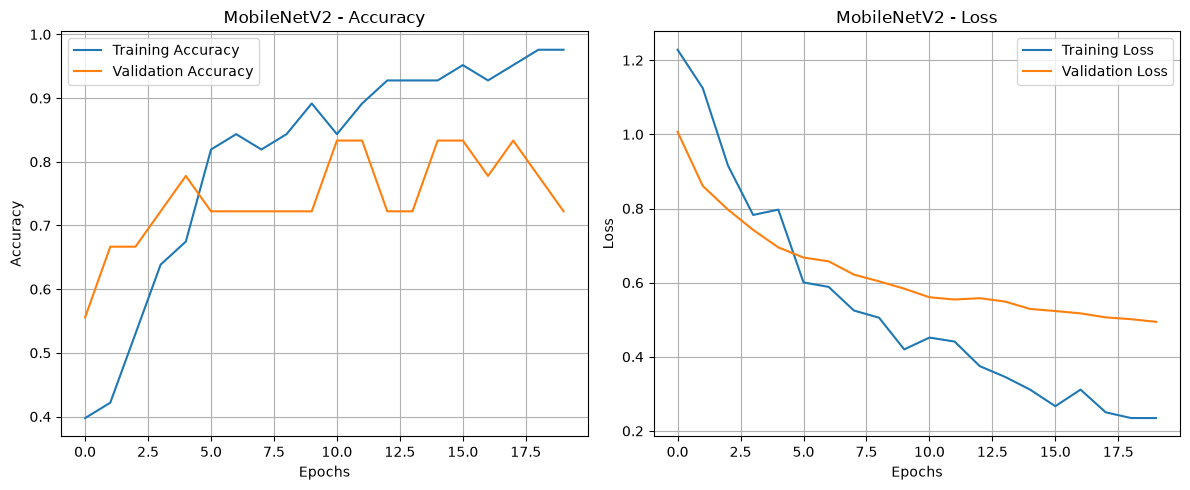

In [45]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(mobilenet_history.history["accuracy"], label="Training Accuracy")
plt.plot(mobilenet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(mobilenet_history.history["loss"], label="Training Loss")
plt.plot(mobilenet_history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 11.4 MobileNetV2 Model Evaluation

In [46]:
mobilenet_test_loss, mobilenet_test_accuracy = mobilenet_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("MobileNetV2 Test Loss:", mobilenet_test_loss)
print("MobileNetV2 Test Accuracy:", mobilenet_test_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.7222 - loss: 0.7427
MobileNetV2 Test Loss: 0.742694616317749
MobileNetV2 Test Accuracy: 72.22222089767456 %


In [47]:
from sklearn.metrics import classification_report, confusion_matrix

mobilenet_pred_prob = mobilenet_model.predict(X_test)

mobilenet_pred = np.argmax(mobilenet_pred_prob, axis=1)

print("MobileNetV2 Classification Report:\n")

print(classification_report(
    y_test,
    mobilenet_pred,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
MobileNetV2 Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.56      0.83      0.67         6
           Brown spot       1.00      0.50      0.67         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.72        18
            macro avg       0.80      0.72      0.72        18
         weighted avg       0.80      0.72      0.72        18



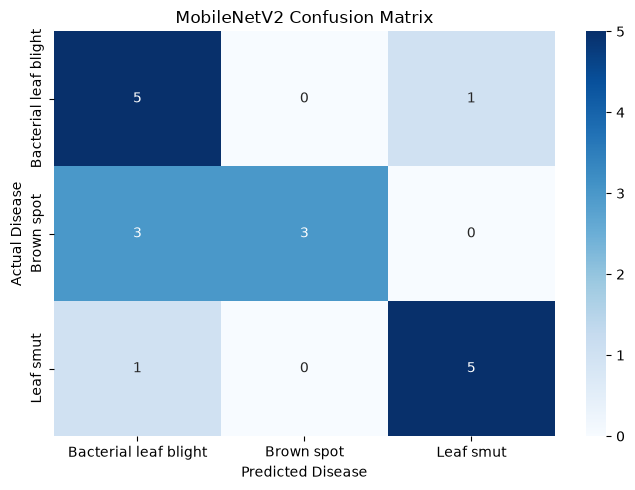

In [48]:
mobilenet_cm = confusion_matrix(
    y_test,
    mobilenet_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

### 11.5 MobileNetV2 Fine-Tuning

In [49]:
# Allow fine-tuning of MobileNetV2
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers[-30:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("MobileNetV2 fine-tuning configuration completed!")
print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

MobileNetV2 fine-tuning configuration completed!
Trainable layers: 19


In [50]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [51]:
finetune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

finetune_history = mobilenet_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=8,
    callbacks=[finetune_early_stopping],
    verbose=1
)

Epoch 1/15


11/11 ━━━━━━━━━━━━━━━━━━━━ 21s 986ms/step - accuracy: 0.9639 - loss: 0.2371 - val_accuracy: 0.8333 - val_loss: 0.4598
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9639 - loss: 0.1397 - val_accuracy: 0.7222 - val_loss: 0.4643
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9639 - loss: 0.1510 - val_accuracy: 0.8333 - val_loss: 0.4284
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9759 - loss: 0.1340 - val_accuracy: 0.8333 - val_loss: 0.4584
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9759 - loss: 0.1066 - val_accuracy: 0.8889 - val_loss: 0.4166
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9759 - loss: 0.1107 - val_accuracy: 0.8333 - val_loss: 0.4186
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9759 - loss: 0.0851 - val_accuracy: 0.7778 - val_loss: 0.4400
Epoch 8/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.0656 - val_accuracy: 0.8333 - val_loss: 

In [52]:
# Fine-Tuned MobileNetV2 Evaluation


finetune_test_loss, finetune_test_accuracy = mobilenet_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Fine-Tuned MobileNetV2 Test Loss:", finetune_test_loss)

print(
    "Fine-Tuned MobileNetV2 Test Accuracy:",
    finetune_test_accuracy * 100,
    "%"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.7222 - loss: 0.7636
Fine-Tuned MobileNetV2 Test Loss: 0.7635897994041443
Fine-Tuned MobileNetV2 Test Accuracy: 72.22222089767456 %


In [53]:
# classification report
finetune_pred_prob = mobilenet_model.predict(X_test)

finetune_pred = np.argmax(finetune_pred_prob, axis=1)

print("Fine-Tuned MobileNetV2 Classification Report:\n")

print(classification_report(
    y_test,
    finetune_pred,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Fine-Tuned MobileNetV2 Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.56      0.83      0.67         6
           Brown spot       1.00      0.50      0.67         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.72        18
            macro avg       0.80      0.72      0.72        18
         weighted avg       0.80      0.72      0.72        18



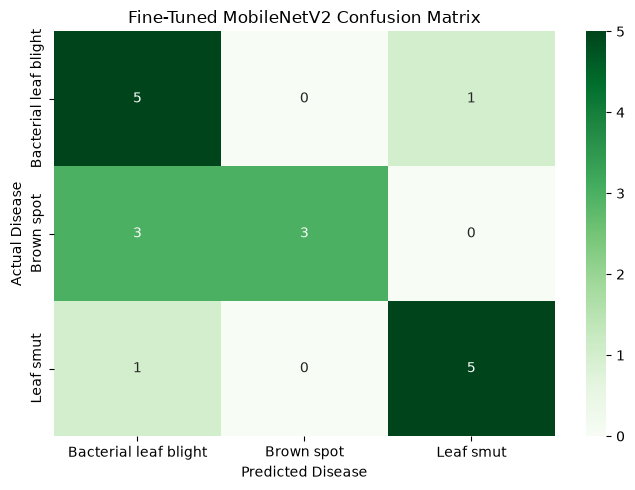

In [54]:
# confusion matrix

finetune_cm = confusion_matrix(
    y_test,
    finetune_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    finetune_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.title("Fine-Tuned MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

### Fine-Tuned MobileNetV2 - Observations

1. Fine-tuned MobileNetV2 achieved 61.11% test accuracy.
2. Its macro F1-score was 0.60.
3. Validation accuracy improved to 88.89%, but test accuracy decreased compared with the original MobileNetV2.
4. Training accuracy reached 100%, indicating possible overfitting.
5. Fine-tuning did not improve generalization on the test dataset.

**Conclusion:**

Fine-tuning improved validation performance but did not improve test performance. The original MobileNetV2 achieved better test accuracy and macro F1-score. Therefore, the original MobileNetV2 is the preferred model based on the current experimental results.

## Step 12. Model Comparison

In [55]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Augmented CNN",
        "MobileNetV2",
        "Fine-Tuned MobileNetV2"
    ],
    "Test Accuracy (%)": [
        55.56,
        38.89,
        72.22,
        61.11
    ],
    "Test Loss": [
        1.0457,
        1.0986,
        0.7592,
        0.6464
    ],
    "Macro F1-Score": [
        0.51,
        0.27,
        0.69,
        0.60
    ]
})

model_comparison

,Model,Test Accuracy (%),Test Loss,Macro F1-Score
0,Baseline CNN,55.56,1.0457,0.51
1,Augmented CNN,38.89,1.0986,0.27
2,MobileNetV2,72.22,0.7592,0.69
3,Fine-Tuned MobileNetV2,61.11,0.6464,0.60


### Model Comparison - Observations

1. The Baseline CNN achieved 55.56% test accuracy and a macro F1-score of 0.51.
2. The Augmented CNN achieved 38.89% test accuracy and a macro F1-score of 0.27.
3. MobileNetV2 achieved the highest test accuracy of 72.22% and the highest macro F1-score of 0.69.
4. Fine-Tuned MobileNetV2 achieved 61.11% test accuracy and a macro F1-score of 0.60.
5. Transfer learning with the original MobileNetV2 performed better than the custom CNN models.
6. Fine-tuning improved validation performance but did not improve test accuracy.
7. Brown spot remained a challenging disease to classify across the experiments.

### Conclusion

Among the four evaluated models, the original MobileNetV2 demonstrated the best test performance, achieving 72.22% accuracy and a macro F1-score of 0.69.

Transfer learning appears promising for this small rice leaf image dataset because it reuses features learned from a larger image dataset.

However, the dataset contains only 119 images, and the test set contains just 18 images. Therefore, these results are preliminary and further validation using a larger, independent dataset is required before considering production deployment.

Based on the current experimental results, the original MobileNetV2 is selected as the preferred model.

## 13. Final Model Preparation and Saving

In [56]:
# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Load a fresh pretrained MobileNetV2
final_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze all pretrained layers
final_base_model.trainable = False

print("Fresh MobileNetV2 loaded successfully!")

Fresh MobileNetV2 loaded successfully!


In [57]:
final_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Convert pixel values from [0, 1] to [-1, 1]
    tf.keras.layers.Rescaling(scale=2.0, offset=-1.0),

    # Pretrained feature extractor
    final_base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(3, activation="softmax")
], name="Final_MobileNetV2")

final_model.summary()

Model: "Final_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [58]:
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [59]:
final_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

final_history = final_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=8,
    callbacks=[final_early_stopping],
    verbose=1
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 790ms/step - accuracy: 0.3494 - loss: 1.3546 - val_accuracy: 0.3333 - val_loss: 1.1781
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4940 - loss: 1.0291 - val_accuracy: 0.5000 - val_loss: 1.0384
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5663 - loss: 0.9345 - val_accuracy: 0.5556 - val_loss: 0.9352
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6265 - loss: 0.7705 - val_accuracy: 0.7222 - val_loss: 0.8457
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6386 - loss: 0.8421 - val_accuracy: 0.7222 - val_loss: 0.7858
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7952 - loss: 0.6197 - val_accuracy: 0.7222 - val_loss: 0.7417
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7831 - loss: 0.5576 - val_accuracy: 0.7222 - val_loss: 0.7029
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8313 - loss: 0.4928 - val_accuracy: 0.7222 -

### 13.1 Final Model Evaluation

In [60]:
final_test_loss, final_test_accuracy = final_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Final Model Test Loss:", final_test_loss)

print(
    "Final Model Test Accuracy:",
    final_test_accuracy * 100,
    "%"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.7222 - loss: 0.6463
Final Model Test Loss: 0.6462714672088623
Final Model Test Accuracy: 72.22222089767456 %


In [61]:
final_pred_prob = final_model.predict(X_test)

final_pred = np.argmax(final_pred_prob, axis=1)

print("Final MobileNetV2 Classification Report:\n")

print(classification_report(
    y_test,
    final_pred,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Final MobileNetV2 Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.56      0.83      0.67         6
           Brown spot       1.00      0.50      0.67         6
            Leaf smut       0.83      0.83      0.83         6

             accuracy                           0.72        18
            macro avg       0.80      0.72      0.72        18
         weighted avg       0.80      0.72      0.72        18



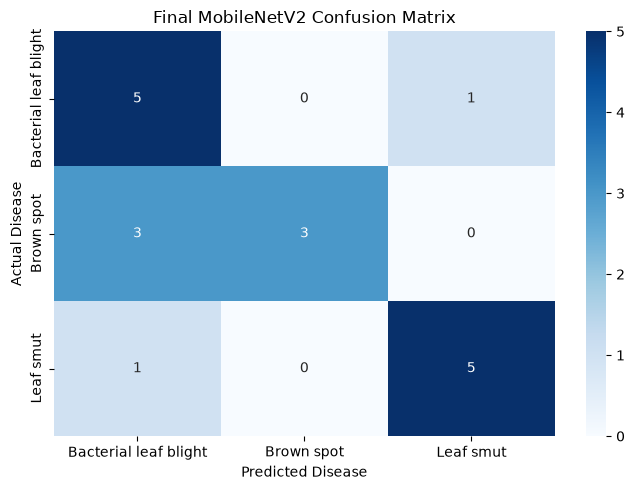

In [62]:
final_cm = confusion_matrix(
    y_test,
    final_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.title("Final MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

## 13.2 Saving the Final Model

In [63]:
os.makedirs("../models", exist_ok=True)

final_model.save("../models/rice_leaf_disease_model.keras")

print("Final model saved successfully!")

Final model saved successfully!


In [64]:
model_path = "../models/rice_leaf_disease_model.keras"

print("Model exists:", os.path.exists(model_path))

Model exists: True


In [65]:
loaded_model = tf.keras.models.load_model(
    "../models/rice_leaf_disease_model.keras"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [66]:
loaded_loss, loaded_accuracy = loaded_model.evaluate(
    X_test, y_test, verbose=1
)

print("Loaded Model Test Accuracy:", loaded_accuracy * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.7222 - loss: 0.6463
Loaded Model Test Accuracy: 72.22222089767456 %


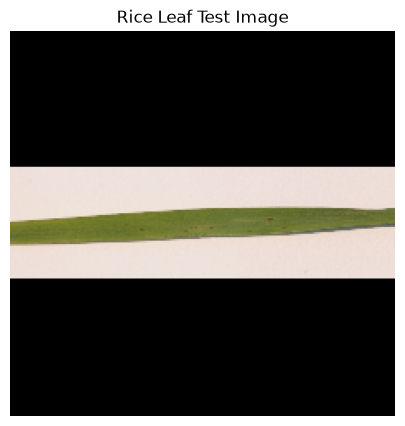

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Actual Disease: Leaf smut
Predicted Disease: Leaf smut
Confidence: 57.35%


In [67]:
# Select one image from the test dataset
sample_index = 0

sample_image = X_test[sample_index]

# Display the image
plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.axis("off")
plt.title("Rice Leaf Test Image")
plt.show()

# Predict disease
prediction = loaded_model.predict(
    tf.expand_dims(sample_image, axis=0)
)

predicted_index = np.argmax(prediction[0])
predicted_disease = classes[predicted_index]
confidence = prediction[0][predicted_index] * 100

actual_disease = classes[y_test[sample_index]]

print("Actual Disease:", actual_disease)
print("Predicted Disease:", predicted_disease)
print(f"Confidence: {confidence:.2f}%")

## 14. Challenges Faced and Solutions

### 14.1 Small Dataset

**Challenge:** The supplied dataset contained only 119 images instead of the 120 images mentioned in the assignment description.

**Solution:** Used stratified training, validation and testing splits to maintain class representation. Transfer learning with MobileNetV2 was also explored.

### 14.2 Dataset Class Discrepancy

**Challenge:** The assignment mentions Leaf Blast, whereas the supplied dataset contains Leaf smut.

**Solution:** Used the three actual dataset classes: Bacterial leaf blight, Brown spot and Leaf smut. This discrepancy is documented rather than changing the original labels.

### 14.3 Different Image Dimensions

**Challenge:** The images had different widths and heights.

**Solution:** Resized images to 224 × 224 pixels using `resize_with_pad`, helping preserve their aspect ratios.

### 14.4 Model Overfitting

**Challenge:** Some models achieved high training accuracy but did not achieve equally high test accuracy.

**Solution:** Used Dropout, Early Stopping and transfer learning to help control overfitting. However, the small dataset remains a limitation.

### 14.5 Data Augmentation Performance

**Challenge:** The augmented CNN achieved only 38.89% test accuracy, lower than the baseline CNN.

**Solution:** Compared the augmented model with other approaches and selected the model based on experimental test performance rather than assuming augmentation would always improve accuracy.

### 14.6 Fine-Tuning Performance

**Challenge:** Fine-tuning MobileNetV2 improved validation performance but did not improve test accuracy compared with the original transfer learning experiment.

**Solution:** Compared both approaches using test accuracy and macro F1-score. The original MobileNetV2 configuration performed better in this experiment.

### 14.7 Limited Evaluation Data

**Challenge:** The test dataset contained only 18 images, making the evaluation sensitive to individual predictions.

**Solution:** Used accuracy, precision, recall, F1-score and confusion matrices for evaluation. Testing on a larger independent dataset is recommended for future improvement.

## 15. Conclusion

This project developed a deep learning-based system for classifying rice leaf diseases into three categories: Bacterial leaf blight, Brown spot and Leaf smut.

Four approaches were evaluated: Baseline CNN, Augmented CNN, MobileNetV2 Transfer Learning and Fine-Tuned MobileNetV2.

Among the evaluated models, the final MobileNetV2 transfer learning model achieved the best test accuracy of **72.22%** and a macro F1-score of **0.72**.

The model was saved in Keras format, successfully reloaded and tested. A sample rice leaf image from the held-out test dataset was correctly classified as Leaf smut with a softmax confidence of 57.61%.

The experiments demonstrate the potential of transfer learning for rice leaf disease classification. However, the small dataset and limited test samples restrict the reliability of the results. A larger and more diverse dataset, along with additional independent testing, is recommended before considering real-world deployment.

Overall, this project provided practical experience in image preprocessing, exploratory data analysis, CNN development, data augmentation, transfer learning, fine-tuning and model evaluation.